In [ ]:
import os
import re
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
uploaded = files.upload()

if len(uploaded) == 0:
    raise RuntimeError("No files uploaded. Please upload all six hourly dataset files.")

print(f"{len(uploaded)} file(s) uploaded successfully.")

Saving duration.csv to duration.csv
Saving e_price.csv to e_price.csv
Saving occupancy.csv to occupancy.csv
Saving s_price.csv to s_price.csv
Saving volume.csv to volume.csv
Saving volume-11kw.csv to volume-11kw.csv
6 file(s) uploaded successfully.


In [ ]:
expected_files = {
    "volume": ["volume.xlsx", "volume.csv"],
    "volume_11kw": ["volume-11kw.xlsx", "volume-11kw.csv"],
    "duration": ["duration.xlsx", "duration.csv"],
    "e_price": ["e_price.xlsx", "e_price.csv"],
    "s_price": ["s_price.xlsx", "s_price.csv"],
    "occupancy": ["occupancy.xlsx", "occupancy.csv"]
}

uploaded_names = set(os.listdir("/content"))
file_map = {}

for key, possible_names in expected_files.items():
    matches = [name for name in possible_names if name in uploaded_names]
    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected one file for {key}. Accepted names: {possible_names}. "
            f"Found: {matches}"
        )
    file_map[key] = matches[0]

print("All six expected dataset files are present.")
for key, filename in file_map.items():
    print(f"{key}: {filename}")

All six expected dataset files are present.
volume: volume.csv
volume_11kw: volume-11kw.csv
duration: duration.csv
e_price: e_price.csv
s_price: s_price.csv
occupancy: occupancy.csv


In [ ]:
def read_dataset(filename):
    extension = Path(filename).suffix.lower()
    if extension == ".xlsx":
        return pd.read_excel(filename)
    if extension == ".xls":
        return pd.read_excel(filename)
    if extension == ".csv":
        return pd.read_csv(filename)
    raise ValueError(f"Unsupported file format: {extension}")

raw_data = {
    key: read_dataset(filename)
    for key, filename in file_map.items()
}

print("All six files loaded successfully.")

for key, dataframe in raw_data.items():
    print(f"{key}: {dataframe.shape}")

All six files loaded successfully.
volume: (4344, 276)
volume_11kw: (4344, 276)
duration: (4344, 276)
e_price: (4344, 276)
s_price: (4344, 276)
occupancy: (4344, 276)


In [ ]:
for key, dataframe in raw_data.items():
    print(f"\n{'=' * 55}\n{key.upper()}\n{'=' * 55}")
    display(dataframe.head())
    print("Shape:", dataframe.shape)
    print("First five column names:", dataframe.columns[:5].tolist())
    print("Data types:")
    print(dataframe.dtypes.head())


VOLUME


,time,102,104,105,106,107,108,109,110,111,...,1156,1159,1162,1163,1164,1166,1167,1168,1172,1173
0,2022-09-01 00:00:00,56.291667,11.083333,60.375000,78.750000,90.125000,71.458333,58.916667,40.250000,65.625000,...,46.666667,134.458333,43.458333,11.083333,224.875000,168.583333,9126.750000,123.666667,6.125000,71.750000
1,2022-09-01 01:00:00,50.458333,9.333333,72.625000,81.666667,100.333333,76.708333,51.916667,43.166667,67.666667,...,39.666667,151.958333,50.458333,9.916667,224.583333,168.875000,9111.000000,111.416667,5.250000,65.333333
2,2022-09-01 02:00:00,55.708333,12.833333,73.208333,89.250000,94.500000,75.833333,58.333333,43.166667,70.000000,...,46.666667,148.166667,44.333333,11.666667,223.125000,165.083333,6961.500000,113.750000,5.250000,67.083333
3,2022-09-01 03:00:00,57.750000,12.541667,67.666667,74.083333,89.541667,80.208333,62.416667,28.000000,72.333333,...,47.250000,146.708333,46.666667,12.833333,234.791667,157.791667,6510.916667,127.166667,6.125000,65.916667
4,2022-09-01 04:00:00,58.333333,11.958333,69.708333,78.166667,88.666667,75.541667,56.583333,42.000000,71.166667,...,44.916667,142.333333,45.791667,11.083333,222.250000,156.625000,6722.166667,114.333333,5.833333,64.750000


Shape: (4344, 276)
First five column names: ['time', '102', '104', '105', '106']
Data types:
time     object
102     float64
104     float64
105     float64
106     float64
dtype: object

VOLUME_11KW


,time,102,104,105,106,107,108,109,110,111,...,1156,1159,1162,1163,1164,1166,1167,1168,1172,1173
0,2022-09-01 00:00:00,56.291667,11.083333,60.375000,78.750000,93.791667,71.458333,58.916667,38.750000,65.625000,...,46.666667,134.458333,43.458333,11.083333,224.875000,168.583333,1380.50,123.666667,6.125000,71.750000
1,2022-09-01 01:00:00,50.458333,9.333333,72.625000,81.666667,104.333333,76.708333,51.916667,41.666667,67.666667,...,39.666667,151.958333,50.458333,9.916667,224.583333,168.875000,1367.50,111.416667,5.250000,65.333333
2,2022-09-01 02:00:00,55.708333,12.833333,73.208333,89.250000,98.833333,75.833333,58.333333,41.666667,70.000000,...,46.666667,148.166667,44.333333,11.666667,223.125000,165.083333,1276.25,113.750000,5.250000,67.083333
3,2022-09-01 03:00:00,57.750000,12.541667,67.666667,74.083333,94.541667,80.208333,62.416667,28.000000,72.333333,...,47.250000,146.708333,46.666667,12.833333,234.791667,157.791667,1287.75,127.166667,6.125000,65.916667
4,2022-09-01 04:00:00,58.333333,11.958333,69.708333,78.166667,93.000000,75.541667,56.583333,40.500000,71.166667,...,44.916667,142.333333,45.791667,11.083333,222.250000,156.625000,1252.25,114.333333,5.833333,64.750000


Shape: (4344, 276)
First five column names: ['time', '102', '104', '105', '106']
Data types:
time     object
102     float64
104     float64
105     float64
106     float64
dtype: object

DURATION


,time,102,104,105,106,107,108,109,110,111,...,1156,1159,1162,1163,1164,1166,1167,1168,1172,1173
0,2022-09-01 00:00:00,8.833333,1.583333,9.166667,11.250000,13.166667,11.250000,8.416667,5.250000,11.916667,...,6.666667,21.833333,6.666667,1.583333,37.500000,24.750000,177.000000,13.666667,1.083333,10.250000
1,2022-09-01 01:00:00,8.166667,1.333333,11.000000,11.666667,14.416667,12.500000,7.416667,5.666667,12.416667,...,5.666667,24.250000,7.833333,1.416667,37.666667,24.750000,175.000000,13.000000,1.166667,9.333333
2,2022-09-01 02:00:00,8.916667,1.916667,11.000000,12.750000,13.666667,12.166667,8.333333,5.666667,12.750000,...,6.666667,23.833333,6.833333,1.666667,36.916667,24.250000,167.250000,12.916667,1.083333,9.583333
3,2022-09-01 03:00:00,9.166667,1.833333,10.000000,10.583333,13.083333,12.583333,8.916667,4.000000,12.916667,...,6.750000,23.666667,7.250000,1.833333,38.416667,23.083333,170.083333,13.833333,1.083333,9.416667
4,2022-09-01 04:00:00,9.250000,1.750000,10.416667,11.166667,12.833333,12.083333,8.083333,5.500000,12.833333,...,6.416667,22.916667,7.083333,1.583333,36.750000,23.000000,164.583333,12.916667,1.166667,9.250000


... (3 outputs left out)

,time,102,104,105,106,107,108,109,110,111,...,1156,1159,1162,1163,1164,1166,1167,1168,1172,1173
0,2022-09-01 00:00:00,0.856,0.76,0.75,0.633333,0.737273,0.76144,0.76,0.758182,0.791818,...,0.76,0.837778,0.7,0.76,0.760162,0.7075,0.758142,0.76,0.76,0.76
1,2022-09-01 01:00:00,0.856,0.76,0.75,0.633333,0.737273,0.76144,0.76,0.758182,0.791818,...,0.76,0.837778,0.7,0.76,0.760162,0.7075,0.758142,0.76,0.76,0.76
2,2022-09-01 02:00:00,0.856,0.76,0.75,0.633333,0.737273,0.76144,0.76,0.758182,0.793636,...,0.76,0.842222,0.7,0.76,0.760162,0.7075,0.758142,0.76,0.76,0.76
3,2022-09-01 03:00:00,0.856,0.76,0.75,0.633333,0.737273,0.76144,0.76,0.758182,0.793636,...,0.76,0.842222,0.7,0.76,0.760162,0.7075,0.758142,0.76,0.76,0.76
4,2022-09-01 04:00:00,0.856,0.76,0.75,0.633333,0.737273,0.76144,0.76,0.758182,0.791818,...,0.76,0.837778,0.7,0.76,0.760162,0.7075,0.758142,0.76,0.76,0.76


Shape: (4344, 276)
First five column names: ['time', '102', '104', '105', '106']
Data types:
time     object
102     float64
104     float64
105     float64
106     float64
dtype: object

OCCUPANCY


,time,102,104,105,106,107,108,109,110,111,...,1156,1159,1162,1163,1164,1166,1167,1168,1172,1173
0,2022-09-01 00:00:00,17.0,1.0,15.0,54.0,23.0,13.0,11.0,6.0,20.0,...,10.0,31.0,9.0,2.0,45.0,26.0,183.0,17.0,2.0,10.0
1,2022-09-01 01:00:00,16.0,1.0,19.0,50.0,25.0,13.0,7.0,12.0,19.0,...,7.0,31.0,8.0,1.0,42.0,25.0,174.0,12.0,2.0,9.0
2,2022-09-01 02:00:00,16.0,1.0,20.0,44.0,24.0,16.0,12.0,6.0,21.0,...,7.0,38.0,9.0,2.0,48.0,24.0,196.0,13.0,2.0,12.0
3,2022-09-01 03:00:00,16.0,1.0,20.0,44.0,22.0,16.0,12.0,6.0,21.0,...,7.0,38.0,9.0,2.0,48.0,24.0,187.0,13.0,2.0,13.0
4,2022-09-01 04:00:00,17.0,1.0,20.0,50.0,24.0,13.0,8.0,12.0,20.0,...,7.0,31.0,8.0,1.0,42.0,25.0,167.0,11.0,2.0,10.0


Shape: (4344, 276)
First five column names: ['time', '102', '104', '105', '106']
Data types:
time     object
102     float64
104     float64
105     float64
106     float64
dtype: object


In [ ]:
data = {}

for key, dataframe in raw_data.items():
    df = dataframe.copy()

    if "time" not in df.columns:
        raise ValueError(f"{key}: the required 'time' column is missing.")

    df["time"] = pd.to_datetime(df["time"], errors="coerce")

    if df["time"].isna().any():
        raise ValueError(f"{key}: invalid or missing timestamps found.")

    df = df.rename(columns={
        column: str(column).strip()
        for column in df.columns
        if column != "time"
    })

    zone_columns = [column for column in df.columns if column != "time"]

    for column in zone_columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")

    df = df.sort_values("time").reset_index(drop=True)
    data[key] = df

print("Column names and data types standardised.")

Column names and data types standardised.


In [ ]:
quality_rows = []

for key, df in data.items():
    numeric = df.drop(columns="time")
    quality_rows.append({
        "dataset": key,
        "rows": len(df),
        "zone_columns": len(numeric.columns),
        "missing_cells": int(df.isna().sum().sum()),
        "duplicate_rows": int(df.duplicated().sum()),
        "duplicate_timestamps": int(df["time"].duplicated().sum()),
        "negative_values": int((numeric < 0).sum().sum()),
        "zero_values": int((numeric == 0).sum().sum())
    })

data_quality_report = pd.DataFrame(quality_rows)
display(data_quality_report)

,dataset,rows,zone_columns,missing_cells,duplicate_rows,duplicate_timestamps,negative_values,zero_values
0,volume,4344,275,0,0,0,0,65170
1,volume_11kw,4344,275,0,0,0,0,65169
2,duration,4344,275,0,0,0,0,65365
3,e_price,4344,275,0,0,0,0,0
4,s_price,4344,275,0,0,0,0,8886
5,occupancy,4344,275,0,0,0,0,32307


In [ ]:
reference = data["volume"]
reference_times = reference["time"]
reference_zones = list(reference.columns.drop("time"))

alignment_rows = []

for key, df in data.items():
    zones = list(df.columns.drop("time"))
    alignment_rows.append({
        "dataset": key,
        "timestamps_match": df["time"].equals(reference_times),
        "zone_ids_match": zones == reference_zones,
        "start_time": df["time"].min(),
        "end_time": df["time"].max(),
        "number_of_zones": len(zones)
    })

alignment_report = pd.DataFrame(alignment_rows)
display(alignment_report)

if not alignment_report["timestamps_match"].all():
    raise ValueError("Timestamp mismatch detected. Do not combine the files.")

if not alignment_report["zone_ids_match"].all():
    raise ValueError("Zone ID mismatch detected. Do not combine the files.")

if len(reference_zones) != 275:
    raise ValueError(f"Expected 275 zones, but found {len(reference_zones)}.")

print("All six files have matching timestamps and zone IDs.")

,dataset,timestamps_match,zone_ids_match,start_time,end_time,number_of_zones
0,volume,True,True,2022-09-01,2023-02-28 23:00:00,275
1,volume_11kw,True,True,2022-09-01,2023-02-28 23:00:00,275
2,duration,True,True,2022-09-01,2023-02-28 23:00:00,275
3,e_price,True,True,2022-09-01,2023-02-28 23:00:00,275
4,s_price,True,True,2022-09-01,2023-02-28 23:00:00,275
5,occupancy,True,True,2022-09-01,2023-02-28 23:00:00,275


All six files have matching timestamps and zone IDs.


In [ ]:
clean_wide = {}

for key, df in data.items():
    cleaned_df = df.copy()
    cleaned_df = cleaned_df.drop_duplicates(subset="time", keep="first")
    zone_columns = [column for column in cleaned_df.columns if column != "time"]

    for column in zone_columns:
        cleaned_df[column] = pd.to_numeric(cleaned_df[column], errors="coerce")
        cleaned_df.loc[cleaned_df[column] < 0, column] = np.nan

    clean_wide[key] = cleaned_df.sort_values("time").reset_index(drop=True)

print("Duplicate timestamps removed where present.")
print("Invalid negative measurements converted to missing values.")

Duplicate timestamps removed where present.
Invalid negative measurements converted to missing values.


In [ ]:
long_data = {}

for key, df in clean_wide.items():
    long_df = df.melt(
        id_vars="time",
        var_name="zone_id",
        value_name=key
    )
    long_df["zone_id"] = long_df["zone_id"].astype(str)
    long_data[key] = long_df

combined = long_data["volume"].copy()

for key in ["volume_11kw", "duration", "e_price", "s_price", "occupancy"]:
    combined = combined.merge(
        long_data[key],
        on=["time", "zone_id"],
        how="outer",
        validate="one_to_one"
    )

combined["time"] = pd.to_datetime(combined["time"])
combined = combined.sort_values(["time", "zone_id"]).reset_index(drop=True)

print("All six datasets combined successfully.")
print("Combined dataset shape:", combined.shape)
display(combined.head())

All six datasets combined successfully.
Combined dataset shape: (1194600, 8)


,time,zone_id,volume,volume_11kw,duration,e_price,s_price,occupancy
0,2022-09-01,1000,330.458333,330.458333,60.833333,0.873429,0.739429,74.0
1,2022-09-01,1009,363.708333,363.708333,55.250000,0.913818,0.748909,66.0
2,2022-09-01,1011,516.833333,516.833333,79.666667,0.880820,0.754302,108.0
3,2022-09-01,1015,147.583333,147.583333,21.083333,1.100000,0.760000,19.0
4,2022-09-01,102,56.291667,56.291667,8.833333,0.924000,0.856000,17.0


In [ ]:
missing_report = pd.DataFrame({
    "column": combined.columns,
    "missing_values": [combined[column].isna().sum() for column in combined.columns],
    "missing_percentage": [
        round(combined[column].isna().mean() * 100, 4)
        for column in combined.columns
    ]
})

display(missing_report)

print("Total missing cells:", int(combined.isna().sum().sum()))

,column,missing_values,missing_percentage
0,time,0,0.0
1,zone_id,0,0.0
2,volume,0,0.0
3,volume_11kw,0,0.0
4,duration,0,0.0
5,e_price,0,0.0
6,s_price,0,0.0
7,occupancy,0,0.0


Total missing cells: 0


In [ ]:
measurement_columns = [
    "volume",
    "volume_11kw",
    "duration",
    "e_price",
    "s_price",
    "occupancy"
]

cleaned = combined.copy()

for column in measurement_columns:
    cleaned[column] = cleaned.groupby("zone_id")[column].transform(
        lambda series: series.interpolate(method="linear", limit_direction="both")
    )

for column in measurement_columns:
    if cleaned[column].isna().any():
        cleaned[column] = cleaned[column].fillna(cleaned[column].median())

print("Missing-value treatment completed.")
print("Remaining missing measurement values:", int(cleaned[measurement_columns].isna().sum().sum()))

Missing-value treatment completed.
Remaining missing measurement values: 0


In [ ]:
cleaned["date"] = cleaned["time"].dt.date
cleaned["hour"] = cleaned["time"].dt.hour
cleaned["day"] = cleaned["time"].dt.day
cleaned["day_of_week"] = cleaned["time"].dt.dayofweek
cleaned["day_name"] = cleaned["time"].dt.day_name()
cleaned["month"] = cleaned["time"].dt.month
cleaned["month_name"] = cleaned["time"].dt.month_name()
cleaned["weekend"] = (cleaned["day_of_week"] >= 5).astype(int)
cleaned["week_of_year"] = cleaned["time"].dt.isocalendar().week.astype(int)

print("Time-based features created.")
display(cleaned.head())

Time-based features created.


,time,zone_id,volume,volume_11kw,duration,e_price,s_price,occupancy,date,hour,day,day_of_week,day_name,month,month_name,weekend,week_of_year
0,2022-09-01,1000,330.458333,330.458333,60.833333,0.873429,0.739429,74.0,2022-09-01,0,1,3,Thursday,9,September,0,35
1,2022-09-01,1009,363.708333,363.708333,55.250000,0.913818,0.748909,66.0,2022-09-01,0,1,3,Thursday,9,September,0,35
2,2022-09-01,1011,516.833333,516.833333,79.666667,0.880820,0.754302,108.0,2022-09-01,0,1,3,Thursday,9,September,0,35
3,2022-09-01,1015,147.583333,147.583333,21.083333,1.100000,0.760000,19.0,2022-09-01,0,1,3,Thursday,9,September,0,35
4,2022-09-01,102,56.291667,56.291667,8.833333,0.924000,0.856000,17.0,2022-09-01,0,1,3,Thursday,9,September,0,35


In [ ]:
outlier_metrics = [
    "volume",
    "volume_11kw",
    "duration",
    "e_price",
    "s_price",
    "occupancy"
]

outlier_records = []

for metric in outlier_metrics:
    for zone_id, group in cleaned.groupby("zone_id"):
        values = group[metric].dropna()

        if len(values) < 4:
            continue

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1
        lower_limit = q1 - 1.5 * iqr
        upper_limit = q3 + 1.5 * iqr

        flagged = group[
            (group[metric] < lower_limit) |
            (group[metric] > upper_limit)
        ]

        for _, row in flagged.iterrows():
            outlier_records.append({
                "time": row["time"],
                "zone_id": zone_id,
                "metric": metric,
                "original_value": row[metric],
                "lower_limit": lower_limit,
                "upper_limit": upper_limit
            })

outlier_details = pd.DataFrame(outlier_records)

if len(outlier_details):
    outlier_summary = (
        outlier_details.groupby("metric")
        .size()
        .reset_index(name="outlier_count")
    )
else:
    outlier_summary = pd.DataFrame(columns=["metric", "outlier_count"])

display(outlier_summary)
print("Total outlier observations detected:", len(outlier_details))

,metric,outlier_count
0,duration,11889
1,e_price,6165
2,occupancy,18985
3,s_price,1768
4,volume,12962
5,volume_11kw,12247


Total outlier observations detected: 64016


In [ ]:
model_ready = cleaned.copy()

for metric in outlier_metrics:

    stats = model_ready.groupby("zone_id")[metric].quantile([0.25, 0.75]).unstack()

    q1 = model_ready["zone_id"].map(stats[0.25])
    q3 = model_ready["zone_id"].map(stats[0.75])

    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    outlier_mask = (
        (model_ready[metric] < lower_limit) |
        (model_ready[metric] > upper_limit)
    )

    model_ready[f"{metric}_outlier_flag"] = outlier_mask.astype(int)

    model_ready[f"{metric}_capped"] = model_ready[metric].clip(
        lower=lower_limit,
        upper=upper_limit
    )

print("Outlier detection and treatment completed successfully.")
print("Original measurement columns preserved.")
print("Outlier flags and capped columns created for Pawni.")

Outlier detection and treatment completed successfully.
Original measurement columns preserved.
Outlier flags and capped columns created for Pawni.


In [ ]:
hourly_summary = (
    cleaned.groupby("time", as_index=False)
    .agg(
        total_volume=("volume", "sum"),
        total_volume_11kw=("volume_11kw", "sum"),
        total_occupancy=("occupancy", "sum"),
        mean_duration=("duration", "mean"),
        mean_e_price=("e_price", "mean"),
        mean_s_price=("s_price", "mean")
    )
)

zone_summary = (
    cleaned.groupby("zone_id", as_index=False)
    .agg(
        total_volume=("volume", "sum"),
        total_volume_11kw=("volume_11kw", "sum"),
        average_occupancy=("occupancy", "mean"),
        average_duration=("duration", "mean"),
        average_e_price=("e_price", "mean"),
        average_s_price=("s_price", "mean")
    )
    .sort_values("total_volume", ascending=False)
)

display(hourly_summary.head())
display(zone_summary.head(10))

,time,total_volume,total_volume_11kw,total_occupancy,mean_duration,mean_e_price,mean_s_price
0,2022-09-01 00:00:00,121029.166667,38861.833333,5753.0,17.564545,0.899585,0.763734
1,2022-09-01 01:00:00,123237.275000,41437.400000,5938.5,18.073636,0.899519,0.763217
2,2022-09-01 02:00:00,109904.191667,39899.775000,6374.5,17.767879,0.899537,0.763946
3,2022-09-01 03:00:00,102283.433333,39852.975000,6310.0,17.814242,0.899610,0.763946
4,2022-09-01 04:00:00,97138.066667,37552.566667,5805.5,17.361818,0.899585,0.763253


,zone_id,total_volume,total_volume_11kw,average_occupancy,average_duration,average_e_price,average_s_price
160,595,2.931878e+07,2.170368e+06,51.728131,45.393550,0.695756,0.523269
76,1167,2.181163e+07,4.081929e+06,137.304558,123.200123,0.784819,0.729727
229,844,1.682888e+07,9.389272e+05,21.812845,19.643416,0.662279,0.607424
167,633,1.500420e+07,1.728799e+06,70.684162,42.229493,0.666416,0.656296
5,1026,1.378514e+07,1.076174e+06,28.735037,25.214856,1.012075,0.716254
215,775,1.338669e+07,6.136404e+05,13.318370,12.809373,0.673419,0.499312
158,592,1.280403e+07,9.418597e+05,27.282113,19.684277,0.997855,0.356984
216,777,1.202707e+07,7.282282e+05,28.564457,17.442622,0.999928,0.537432
181,690,1.174409e+07,1.032073e+06,24.753683,21.980682,0.921799,0.616858
120,346,8.429800e+06,8.429800e+06,23.417357,13.843712,0.784738,0.715185


In [ ]:
chart_folder = Path("EV_Charging_Charts")
chart_folder.mkdir(exist_ok=True)

original_show = plt.show
chart_counter = {"count": 0}

def save_chart_before_show(*args, **kwargs):
    chart_counter["count"] += 1

    plt.gcf().savefig(
        chart_folder / f"chart_{chart_counter['count']:02d}.png",
        dpi=180,
        bbox_inches="tight"
    )

    original_show(*args, **kwargs)

plt.show = save_chart_before_show

print("Chart-saving setup activated successfully.")

Chart-saving setup activated successfully.


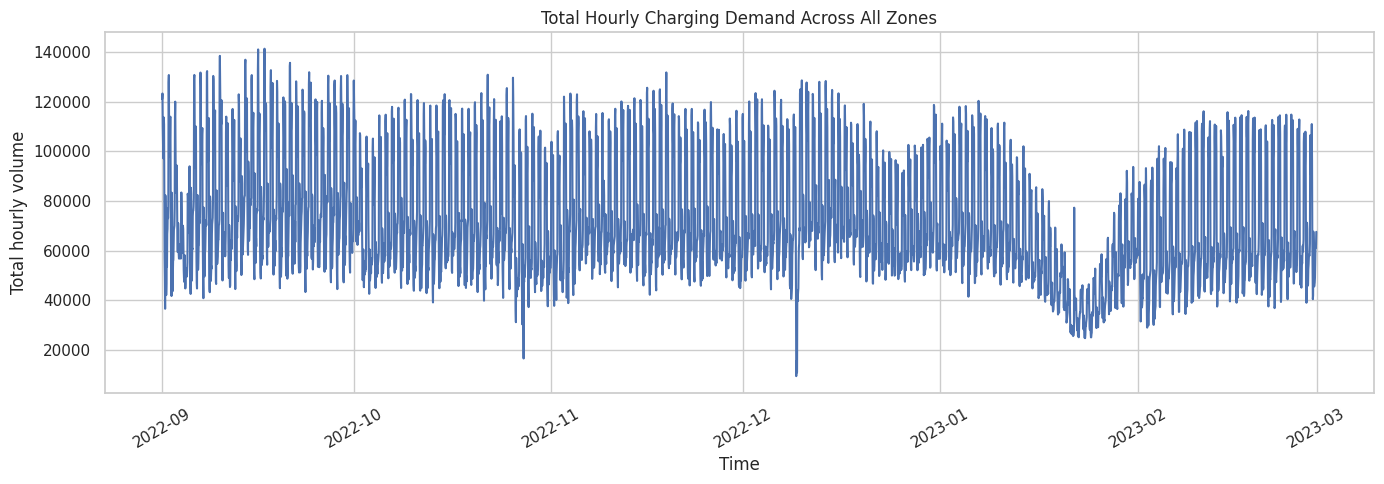

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(hourly_summary["time"], hourly_summary["total_volume"])
plt.title("Total Hourly Charging Demand Across All Zones")
plt.xlabel("Time")
plt.ylabel("Total hourly volume")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

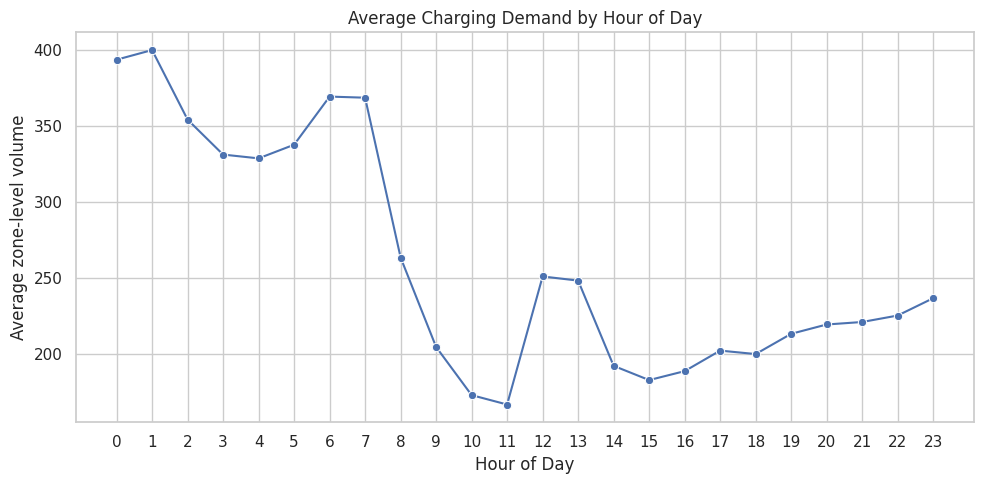

In [ ]:
hour_demand = cleaned.groupby("hour")["volume"].mean()

plt.figure(figsize=(10, 5))
sns.lineplot(x=hour_demand.index, y=hour_demand.values, marker="o")
plt.xticks(range(24))
plt.title("Average Charging Demand by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Average zone-level volume")
plt.tight_layout()
plt.show()

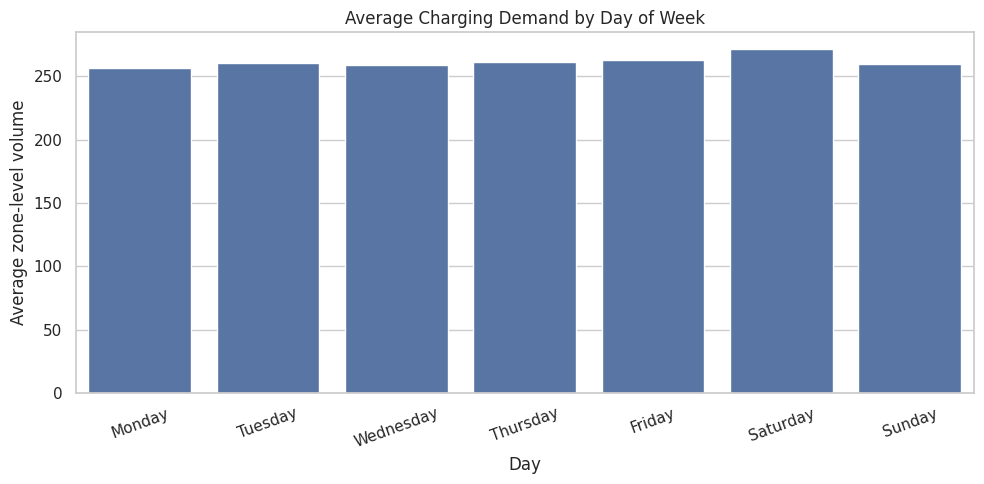

In [ ]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_demand = cleaned.groupby("day_name")["volume"].mean().reindex(day_order)

plt.figure(figsize=(10, 5))
sns.barplot(x=day_demand.index, y=day_demand.values)
plt.title("Average Charging Demand by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average zone-level volume")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

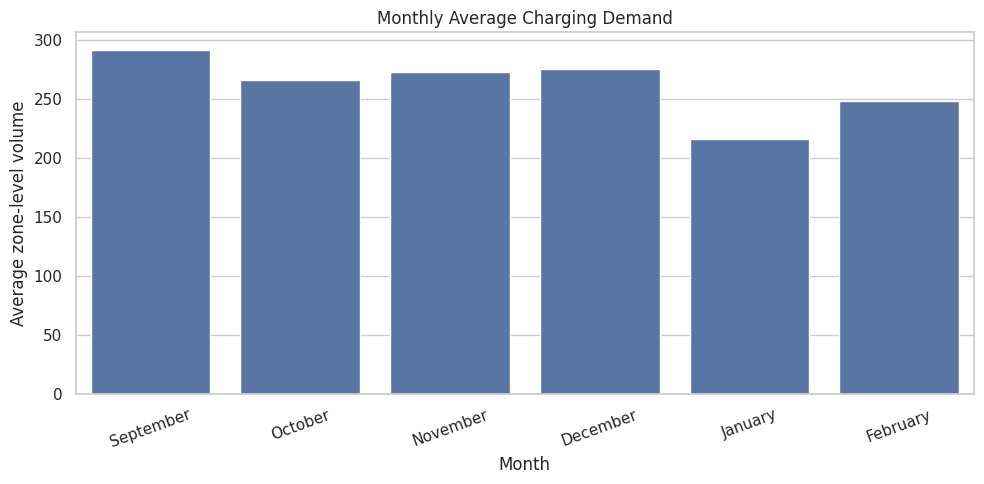

In [ ]:
month_demand = cleaned.groupby("month_name")["volume"].mean()
month_order = ["September", "October", "November", "December", "January", "February"]
month_demand = month_demand.reindex(month_order)

plt.figure(figsize=(10, 5))
sns.barplot(x=month_demand.index, y=month_demand.values)
plt.title("Monthly Average Charging Demand")
plt.xlabel("Month")
plt.ylabel("Average zone-level volume")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

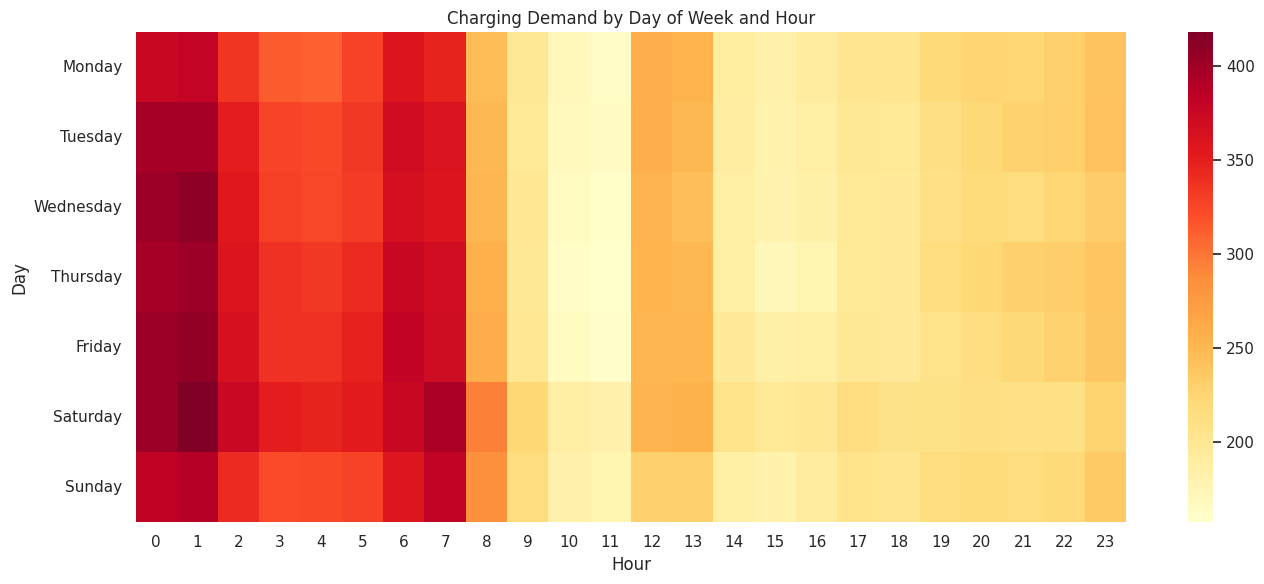

In [ ]:
heatmap_data = cleaned.pivot_table(
    index="day_name",
    columns="hour",
    values="volume",
    aggfunc="mean"
).reindex(day_order)

plt.figure(figsize=(14, 6))
sns.heatmap(heatmap_data, cmap="YlOrRd")
plt.title("Charging Demand by Day of Week and Hour")
plt.xlabel("Hour")
plt.ylabel("Day")
plt.tight_layout()
plt.show()

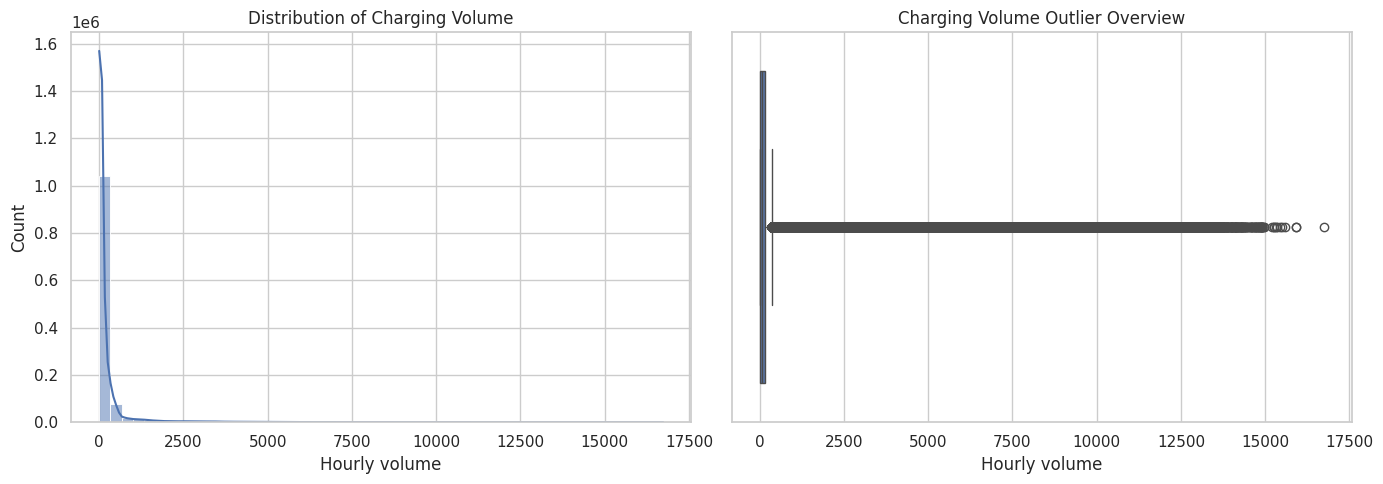

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(cleaned["volume"], bins=50, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Charging Volume")
axes[0].set_xlabel("Hourly volume")

sns.boxplot(x=cleaned["volume"], ax=axes[1])
axes[1].set_title("Charging Volume Outlier Overview")
axes[1].set_xlabel("Hourly volume")

plt.tight_layout()
plt.show()

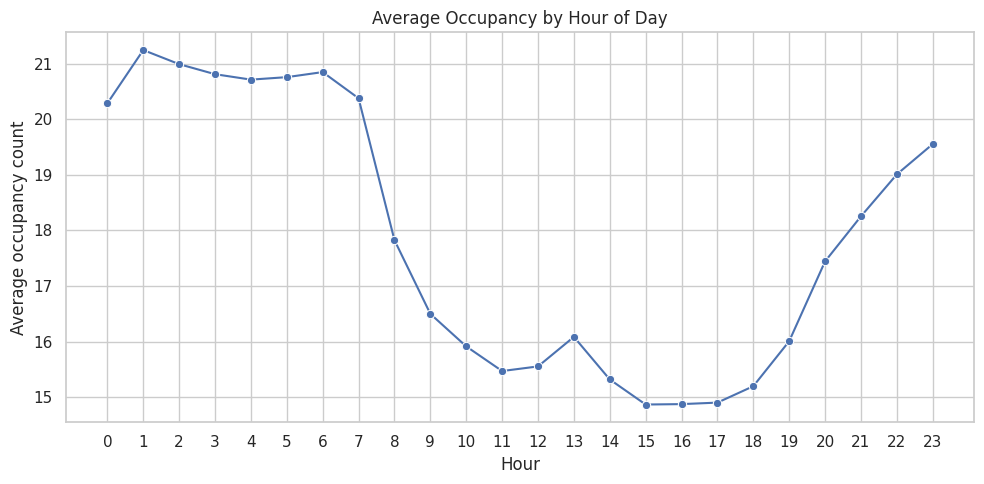

In [ ]:
occupancy_by_hour = cleaned.groupby("hour")["occupancy"].mean()

plt.figure(figsize=(10, 5))
sns.lineplot(x=occupancy_by_hour.index, y=occupancy_by_hour.values, marker="o")
plt.xticks(range(24))
plt.title("Average Occupancy by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Average occupancy count")
plt.tight_layout()
plt.show()

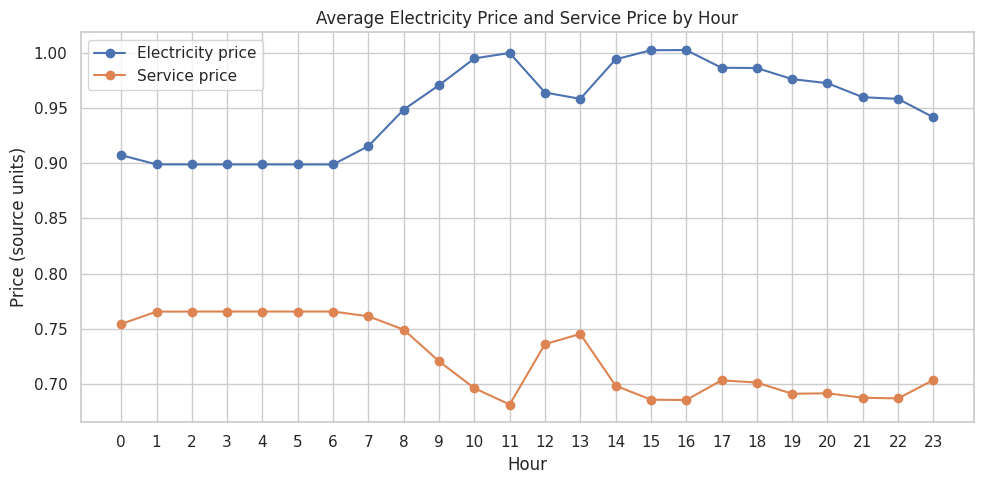

In [ ]:
price_by_hour = cleaned.groupby("hour")[["e_price", "s_price"]].mean()

plt.figure(figsize=(10, 5))
plt.plot(price_by_hour.index, price_by_hour["e_price"], marker="o", label="Electricity price")
plt.plot(price_by_hour.index, price_by_hour["s_price"], marker="o", label="Service price")
plt.xticks(range(24))
plt.title("Average Electricity Price and Service Price by Hour")
plt.xlabel("Hour")
plt.ylabel("Price (source units)")
plt.legend()
plt.tight_layout()
plt.show()

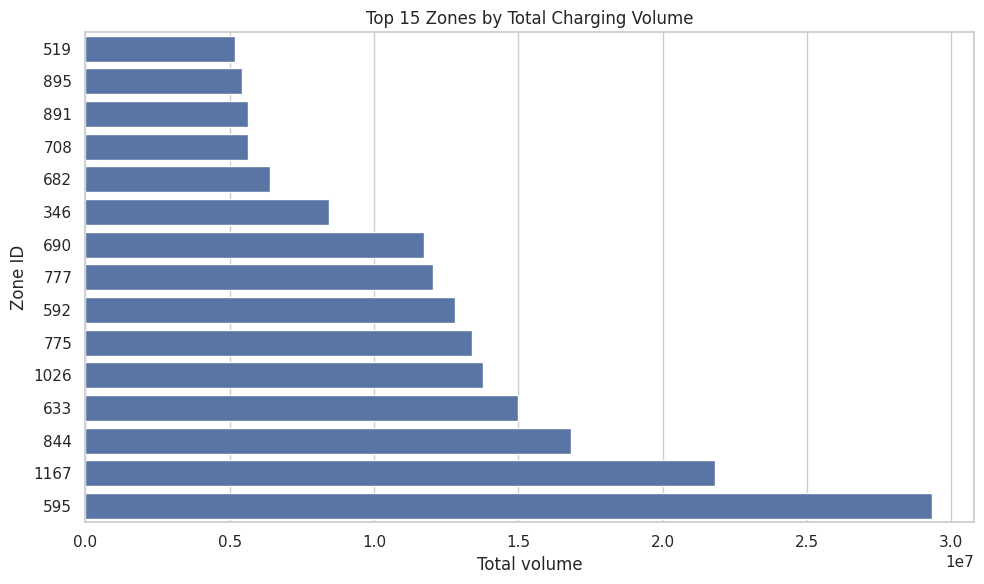

In [ ]:
top_zones = zone_summary.head(15).sort_values("total_volume")

plt.figure(figsize=(10, 6))
sns.barplot(data=top_zones, x="total_volume", y="zone_id")
plt.title("Top 15 Zones by Total Charging Volume")
plt.xlabel("Total volume")
plt.ylabel("Zone ID")
plt.tight_layout()
plt.show()

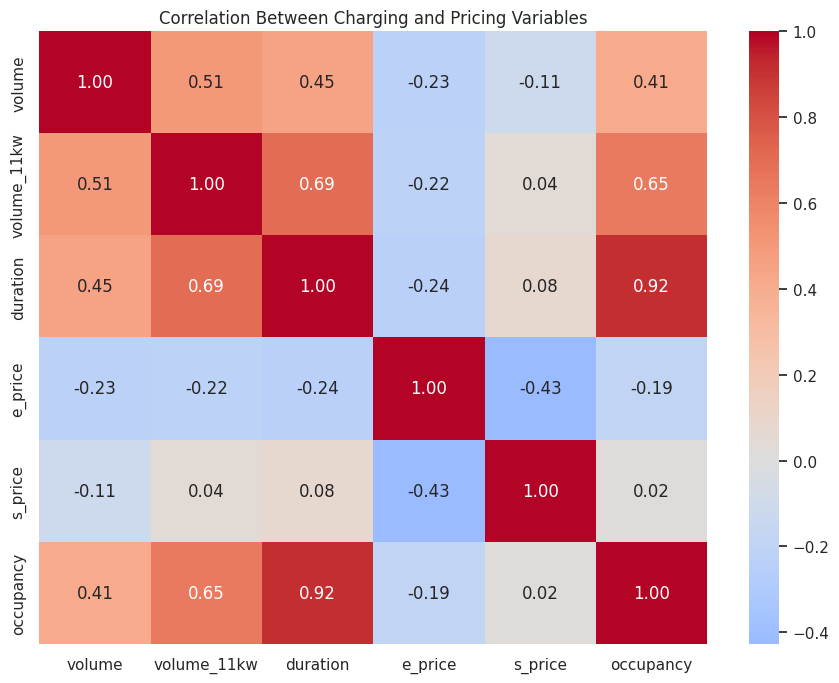

In [ ]:
correlation_data = cleaned[
    ["volume", "volume_11kw", "duration", "e_price", "s_price", "occupancy"]
].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(correlation_data, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Between Charging and Pricing Variables")
plt.tight_layout()
plt.show()

In [ ]:
plt.show = original_show

print("All visualizations saved successfully.")
print("Total charts saved:", chart_counter["count"])

All visualizations saved successfully.
Total charts saved: 10


In [ ]:
peak_hour = int(hour_demand.idxmax())
lowest_hour = int(hour_demand.idxmin())
peak_day = str(day_demand.idxmax())
lowest_day = str(day_demand.idxmin())
highest_zone = str(zone_summary.iloc[0]["zone_id"])

findings = [
    f"Highest average demand hour: {peak_hour}:00.",
    f"Lowest average demand hour: {lowest_hour}:00.",
    f"Highest average demand day: {peak_day}.",
    f"Lowest average demand day: {lowest_day}.",
    f"Highest-demand zone by total volume: {highest_zone}.",
    f"Outlier observations flagged: {len(outlier_details)}.",
    "Outliers are retained in original columns and capped values are provided separately."
]

for finding in findings:
    print("-", finding)

- Highest average demand hour: 1:00.
- Lowest average demand hour: 11:00.
- Highest average demand day: Saturday.
- Lowest average demand day: Monday.
- Highest-demand zone by total volume: 595.
- Outlier observations flagged: 64016.
- Outliers are retained in original columns and capped values are provided separately.


In [ ]:
from pathlib import Path

output_folder = Path("EV_Charging_Final_Output")
output_folder.mkdir(exist_ok=True)

cleaned.to_csv(output_folder / "cleaned_hourly_zone_dataset.csv", index=False)
model_ready.to_csv(output_folder / "model_ready_hourly_dataset.csv", index=False)

hourly_summary.to_csv(output_folder / "hourly_system_summary.csv", index=False)
zone_summary.to_csv(output_folder / "zone_level_summary.csv", index=False)

data_quality_report.to_csv(output_folder / "data_quality_report.csv", index=False)
alignment_report.to_csv(output_folder / "file_alignment_report.csv", index=False)
missing_report.to_csv(output_folder / "missing_value_report.csv", index=False)

outlier_details.to_csv(output_folder / "outlier_details.csv", index=False)
outlier_summary.to_csv(output_folder / "outlier_summary.csv", index=False)

with open(output_folder / "key_findings.txt", "w", encoding="utf-8") as file:
    file.write("\n".join(findings))

print("All cleaned datasets and reports exported successfully.")

All cleaned datasets and reports exported successfully.


In [ ]:
import shutil

source_chart_folder = Path("EV_Charging_Charts")
final_chart_folder = output_folder / "visualisations"
final_chart_folder.mkdir(exist_ok=True)

if not source_chart_folder.exists():
    raise FileNotFoundError("Saved chart folder not found.")

chart_files = list(source_chart_folder.glob("*.png"))

if len(chart_files) != 10:
    raise ValueError(f"Expected 10 charts, but found {len(chart_files)}.")

for chart in chart_files:
    shutil.copy2(chart, final_chart_folder / chart.name)

print("All visualizations copied successfully.")
print("Total PNG charts:", len(list(final_chart_folder.glob("*.png"))))

All visualizations copied successfully.
Total PNG charts: 10


In [ ]:
import zipfile
from google.colab import files

zip_filename = "EV_Charging_Data_Analysis_Complete.zip"

with zipfile.ZipFile(zip_filename, "w", zipfile.ZIP_DEFLATED) as zip_file:
    for file_path in output_folder.rglob("*"):
        if file_path.is_file():
            zip_file.write(
                file_path,
                arcname=file_path.relative_to(output_folder)
            )

print("Final project package created successfully.")

files.download(zip_filename)

Final project package created successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>